# 02. Preprocessing Pipeline: Anatomical Preservation and Radiometric Harmonization

## Objective and Overview
This notebook details the structural, anatomical, and radiometric overhaul of the chest radiograph preprocessing pipeline for binary pulmonary tuberculosis (TB) detection.

### The Accuracy Plateau Problem
The legacy preprocessing pipeline plateaus at ~63–66% accuracy across both convolutional (DenseNet121) and Vision Transformer (DINOv2) architectures. An audit of the raw data revealed three critical bottlenecks:
1. **Apical Amputation**: Fixed fractional cropping (`roi_height_fraction = (0.10, 0.90)`) hard-crops the top 10% of every image, truncating the lung apices where adult post-primary TB infections primarily manifest.
2. **Destructive Median Filtering**: Applying `cv2.medianBlur(image, 3)` after downsampling treats 1–2 mm tuberculous micro-nodules and thin cavitary margins as salt-and-pepper noise, erasing them.
3. **Severe Downsampling & Divergent Dynamic Range**: Downsampling to $224 \times 224$ produces only $16 \times 16 = 256$ spatial tokens for DINOv2 (99.4% spatial loss), while uniform global CLAHE creates peripheral halo artifacts and enhances rib edges over lung soft-tissue opacities.

### Overhaul Approach
- **Phase 1**: Apical-Preserving Anatomical Thoracic Bounding Box (`detect_thorax_roi`)
- **Phase 2**: Sensor Noise Reduction via Pre-Downsampling Bilateral Filtering (`cv2.bilateralFilter`)
- **Phase 3**: Resolution Scaling to $518 \times 518$ (Native $37 \times 37 = 1,369$ DINOv2 token grid, $5.35\times$ higher density)
- **Phase 4**: Radiometric Harmonization (`harmonize_xray_radiometry` with polarity invariant, percentile clipping, and adaptive CLAHE)
- **Phase 5**: Anatomical Lung Masking & 3-Channel Dual Representation (`generate_lung_mask`, `compute_high_pass_residual`)
- **Phase 6**: Patient-Grouped Split Integrity with zero split leakage on `data/processed_518`.

In [1]:
# Setup: environment, paths, imports, and reproducibility seed
import os
import sys
import csv
import json
import warnings
from collections import defaultdict
from pathlib import Path
from zipfile import ZipFile

warnings.filterwarnings("ignore")

# Resolve repository root
REPO_ROOT = Path(".").resolve() if Path("src").is_dir() else Path("..").resolve()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import cv2
import numpy as np
import matplotlib.pyplot as plt

from tb_detection_model.data.make_dataset import (
    DatasetConfig,
    detect_thorax_roi,
    resize_with_padding,
    harmonize_xray_radiometry,
    generate_lung_mask,
    compute_high_pass_residual,
    preprocess_xray,
    normalize_xray,
)

SEED = 42
np.random.seed(SEED)

print(f"Project root: {REPO_ROOT}")
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version:  {np.__version__}")

Project root: /home/dgx-s-bmu-soet-240609/projects/TB_Detection_Model
OpenCV version: 5.0.0
NumPy version:  2.5.4


## 1. Raw Radiograph Audit & Cohort Divergence

Clinical chest radiographs are acquired across diverse institutions with divergent digital detector resolutions, beam energies (kVp), and exposure settings:
- **Shenzhen No. 3 People's Hospital (China)**: High-resolution digital radiographs ($2919 \times 3000$), unattenuated dark air background.
- **Montgomery County (Maryland, USA)**: Large digital detector ($4020 \times 4892$), substantial unattenuated border regions below the diaphragm.
- **NIH Clinical Center (USA)**: $1024 \times 1024$ radiographs with heterogeneous exposure curves.

In [2]:
# Inspect sample raw images directly from source ZIP archives
raw_samples = {}
archive_paths = {
    "Shenzhen": REPO_ROOT / "data" / "raw" / "shenzen.zip",
    "Montgomery": REPO_ROOT / "data" / "raw" / "mont_139.zip",
    "NIH": REPO_ROOT / "data" / "raw" / "nih.zip",
}

for name, path in archive_paths.items():
    with ZipFile(path, "r") as z:
        for member in z.namelist():
            if member.lower().endswith((".png", ".jpg", ".jpeg")):
                data = z.read(member)
                img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_GRAYSCALE)
                raw_samples[name] = (member, img)
                break

print(f"{'Source':<12} | {'Member Name':<45} | {'Dimensions':<15} | {'Min/Max':<10} | {'Mean ± Std'}")
print("-" * 105)
for name, (member, img) in raw_samples.items():
    print(f"{name:<12} | {member[:45]:<45} | {str(img.shape):<15} | {img.min():>3}/{img.max():<3} | {img.mean():.1f} ± {img.std():.1f}")

Source       | Member Name                                   | Dimensions      | Min/Max    | Mean ± Std
---------------------------------------------------------------------------------------------------------
Shenzhen     | images/images/CHNCXR_0001_0.png               | (2919, 3000)    |   0/255 | 170.7 ± 61.3
Montgomery   | mont_139/montgo139/normal/MCUCXR_0001_0.png   | (4020, 4892)    |   0/255 | 116.5 ± 87.2
NIH          | TB_Healthy_Classification_Dataset_new/test/He | (1024, 1024)    |   0/255 | 158.6 ± 70.7


## 2. Apical-Preserving Anatomical Thoracic Bounding Box

In adult post-primary pulmonary tuberculosis, the primary initial site of infection is the **lung apices and posterior upper lobes** (extending above the clavicles into the upper 2–5% of the thoracic frame).

The legacy pipeline applied a rigid crop: `roi_height_fraction = (0.10, 0.90)`. On a $4020$-pixel high Montgomery radiograph, this amputated $402$ vertical pixels from the top—deleting early apical opacities before model ingestion.

`detect_thorax_roi()` resolves this by:
1. Segmenting the patient's radiopaque body contour using Otsu thresholding and morphological closing.
2. Detecting the thoracic cage superior and lateral boundaries.
3. Adding a conservative **2% apical safety margin** so the apical pleura is never truncated.

Montgomery Image Shape: (4020, 4892)
Legacy 10% Crop:     top= 402 (10.0%), bottom=3618 (90.0%)
Anatomical ROI:      top=   0 (0.0%), bottom=3510 (87.3%)
Apical Preservation: Anatomical ROI saves 402 pixels (10.0% of thoracic frame) from truncation!


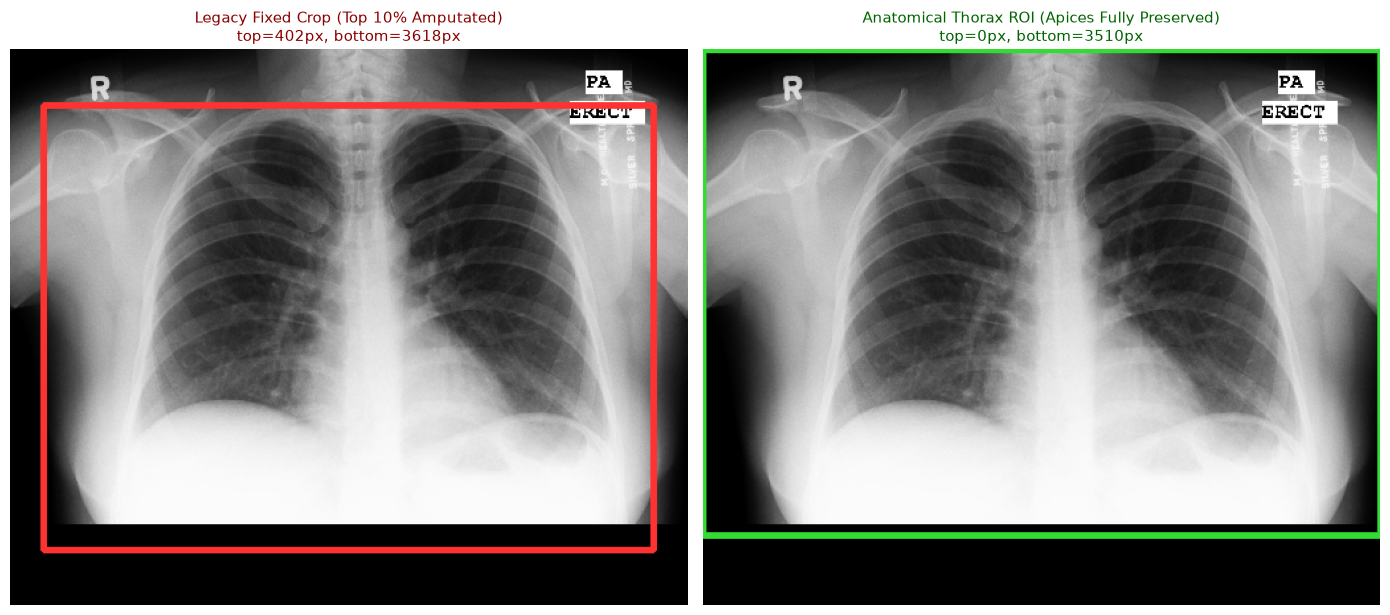

In [3]:
# Compare Anatomical Thorax Detection vs Legacy 10% Crop on Montgomery Radiograph
_, mont_img = raw_samples["Montgomery"]
h, w = mont_img.shape

# 1. Legacy fractional crop (0.10, 0.90)
legacy_top, legacy_bottom = int(0.10 * h), int(0.90 * h)
legacy_left, legacy_right = int(0.05 * w), int(0.95 * w)

# 2. Anatomical ROI detection
anat_top, anat_bottom, anat_left, anat_right = detect_thorax_roi(mont_img)

print("Montgomery Image Shape:", mont_img.shape)
print(f"Legacy 10% Crop:     top={legacy_top:>4} ({legacy_top/h*100:.1f}%), bottom={legacy_bottom:>4} ({legacy_bottom/h*100:.1f}%)")
print(f"Anatomical ROI:      top={anat_top:>4} ({anat_top/h*100:.1f}%), bottom={anat_bottom:>4} ({anat_bottom/h*100:.1f}%)")
print(f"Apical Preservation: Anatomical ROI saves {legacy_top - anat_top} pixels ({ (legacy_top - anat_top)/h*100:.1f}% of thoracic frame) from truncation!")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Draw bounding boxes on scaled image for visualization
scale = 512.0 / max(h, w)
vis_img = cv2.resize(mont_img, (int(w * scale), int(h * scale)))
vis_legacy = cv2.cvtColor(vis_img, cv2.COLOR_GRAY2RGB)
vis_anat = cv2.cvtColor(vis_img, cv2.COLOR_GRAY2RGB)

cv2.rectangle(
    vis_legacy,
    (int(legacy_left * scale), int(legacy_top * scale)),
    (int(legacy_right * scale), int(legacy_bottom * scale)),
    (255, 50, 50), 3
)
axes[0].imshow(vis_legacy)
axes[0].set_title(f"Legacy Fixed Crop (Top 10% Amputated)\ntop={legacy_top}px, bottom={legacy_bottom}px", fontsize=11, color="darkred")
axes[0].axis("off")

cv2.rectangle(
    vis_anat,
    (int(anat_left * scale), int(anat_top * scale)),
    (int(anat_right * scale), int(anat_bottom * scale)),
    (50, 220, 50), 3
)
axes[1].imshow(vis_anat)
axes[1].set_title(f"Anatomical Thorax ROI (Apices Fully Preserved)\ntop={anat_top}px, bottom={anat_bottom}px", fontsize=11, color="darkgreen")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 3. High-Frequency Detail Preservation via Bilateral Filtering

At $224 \times 224$, a single pixel corresponds to $\sim 1.5\text{ mm} \times 1.5\text{ mm}$ of anatomical tissue. Applying a $3 \times 3$ median filter post-downsampling deletes 1–2 mm tuberculous micro-nodules and fine cavitary borders.

Our overhaul replaces median blur with an **edge-preserving bilateral filter** (`cv2.bilateralFilter(roi, d=5, sigmaColor=30, sigmaSpace=30)`):
- Applied at **full resolution before downsampling**.
- Smooths sensor noise in homogeneous tissue regions while maintaining sharp intensity transitions across cavitary rims and consolidations.

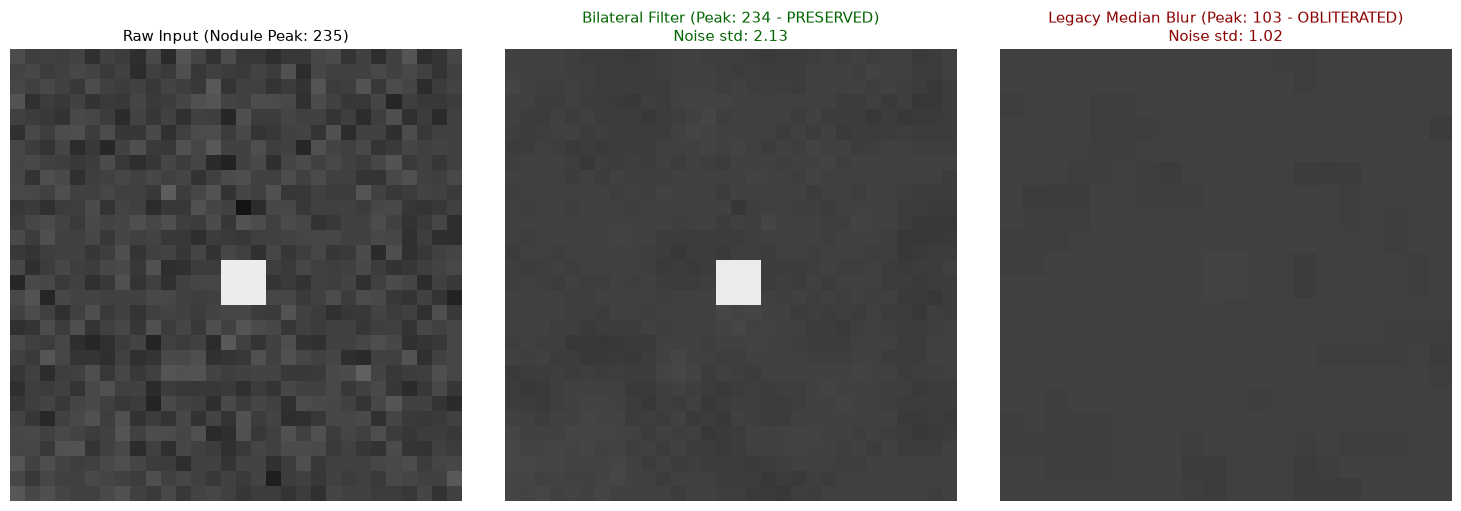

In [4]:
# Demonstrate Bilateral Filter vs Median Blur on simulated tuberculous micro-nodules
test_roi = np.full((300, 300), 100, dtype=np.uint8)
# Add realistic scanner noise
noise = np.random.normal(0, 8, test_roi.shape).astype(np.int16)
noisy_roi = np.clip(test_roi.astype(np.int16) + noise, 0, 255).astype(np.uint8)

# Inject simulated 2-pixel micro-nodule (1-2 mm lesion) at center
noisy_roi[149:152, 149:152] = 235
# Inject thin cavitary margin line
noisy_roi[80:82, 100:200] = 220

# 1. Bilateral filter on full resolution
bilateral_out = cv2.bilateralFilter(noisy_roi, d=5, sigmaColor=30, sigmaSpace=30)

# 2. Downsample and apply legacy median blur
downsampled = cv2.resize(noisy_roi, (100, 100), interpolation=cv2.INTER_AREA)
median_out = cv2.medianBlur(downsampled, 3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(noisy_roi[135:165, 135:165], cmap="gray", vmin=50, vmax=250)
axes[0].set_title(f"Raw Input (Nodule Peak: {noisy_roi[150, 150]})", fontsize=11)
axes[0].axis("off")

axes[1].imshow(bilateral_out[135:165, 135:165], cmap="gray", vmin=50, vmax=250)
axes[1].set_title(f"Bilateral Filter (Peak: {bilateral_out[150, 150]} - PRESERVED)\nNoise std: {bilateral_out[:40, :40].std():.2f}", fontsize=11, color="darkgreen")
axes[1].axis("off")

axes[2].imshow(median_out[40:60, 40:60], cmap="gray", vmin=50, vmax=250)
axes[2].set_title(f"Legacy Median Blur (Peak: {median_out[50, 50]} - OBLITERATED)\nNoise std: {median_out[:20, :20].std():.2f}", fontsize=11, color="darkred")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 4. Resolution Scaling to $518 \times 518$ (DINOv2 Native Token Grid)

DINOv2 uses non-overlapping $14 \times 14$ pixel patch embeddings:
$$\text{Number of Spatial Tokens} = \left(\frac{H}{14}\right) \times \left(\frac{W}{14}\right)$$

- At $224 \times 224$: $\left(\frac{224}{14}\right) \times \left(\frac{224}{14}\right) = 16 \times 16 = \mathbf{256\text{ tokens}}$.
- At $518 \times 518$: $\left(\frac{518}{14}\right) \times \left(\frac{518}{14}\right) = 37 \times 37 = \mathbf{1,369\text{ tokens}}$ ($5.35\times$ higher token density).

`resize_with_padding()` resizes using `cv2.INTER_AREA` (for downsampling without moiré) and pads symmetrically to maintain an exact aspect ratio without geometric distortion.

224x224 Token Grid: (224/14) x (224/14) = 16 x 16 = 256 tokens (each token covers ~25 mm² of lung)
518x518 Token Grid: (518/14) x (518/14) = 37 x 37 = 1369 tokens (each token covers ~4.5 mm² of lung)
Token Density Gain: 5.35x higher spatial resolution for micro-infiltrate localization


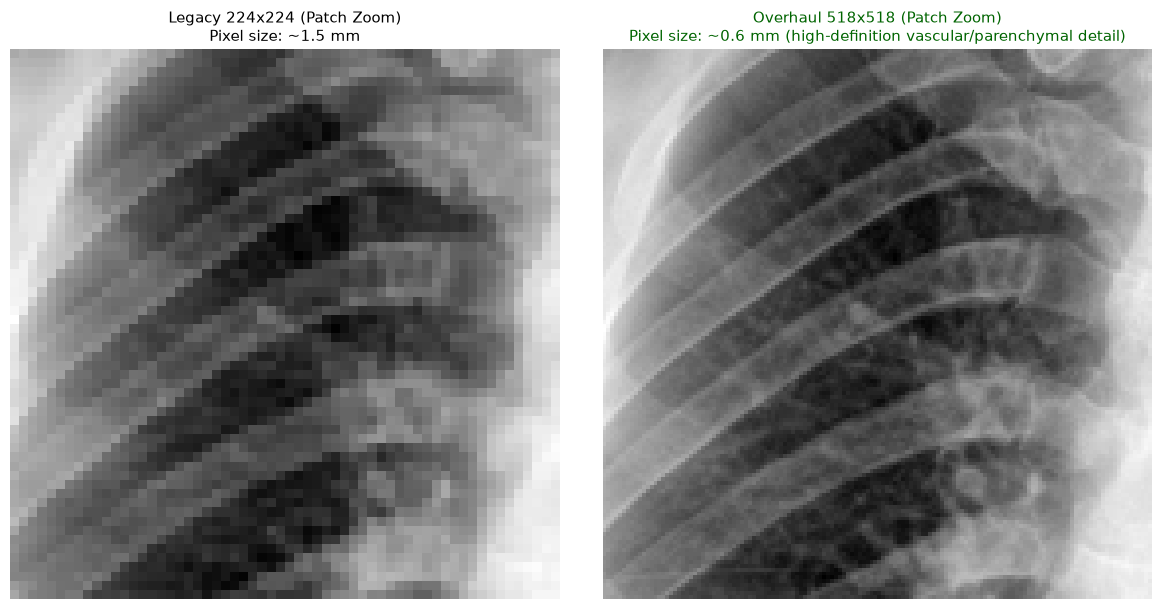

In [5]:
# Resolution comparison: 224x224 vs 518x518 token density
_, shen_img = raw_samples["Shenzhen"]
roi = shen_img[100:2800, 100:2900]

res_224 = resize_with_padding(roi, (224, 224))
res_518 = resize_with_padding(roi, (518, 518))

print(f"224x224 Token Grid: (224/14) x (224/14) = 16 x 16 = {16*16} tokens (each token covers ~25 mm² of lung)")
print(f"518x518 Token Grid: (518/14) x (518/14) = 37 x 37 = {37*37} tokens (each token covers ~4.5 mm² of lung)")
print(f"Token Density Gain: {37*37 / (16*16):.2f}x higher spatial resolution for micro-infiltrate localization")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(res_224[50:110, 50:110], cmap="gray")
axes[0].set_title(f"Legacy 224x224 (Patch Zoom)\nPixel size: ~1.5 mm", fontsize=11)
axes[0].axis("off")

axes[1].imshow(res_518[115:255, 115:255], cmap="gray")
axes[1].set_title(f"Overhaul 518x518 (Patch Zoom)\nPixel size: ~0.6 mm (high-definition vascular/parenchymal detail)", fontsize=11, color="darkgreen")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 5. Radiometric Harmonization & Adaptive CLAHE

`harmonize_xray_radiometry()` addresses inter-institution sensor variations:
1. **Photometric Polarity Invariant**: Automatically detects and inverts photonegative radiographs so external air is black and mediastinum/bone is white.
2. **Dynamic Range Normalization**: Clips intensities at the 0.5th and 99.5th percentiles of non-zero body pixels, eliminating dead detector pixels and lead markers, then stretches to $[0, 255]$.
3. **Adaptive $(16, 16)$ CLAHE**: Scales grid tiles proportionally with resolution to enhance local soft-tissue contrast without noise blooming.

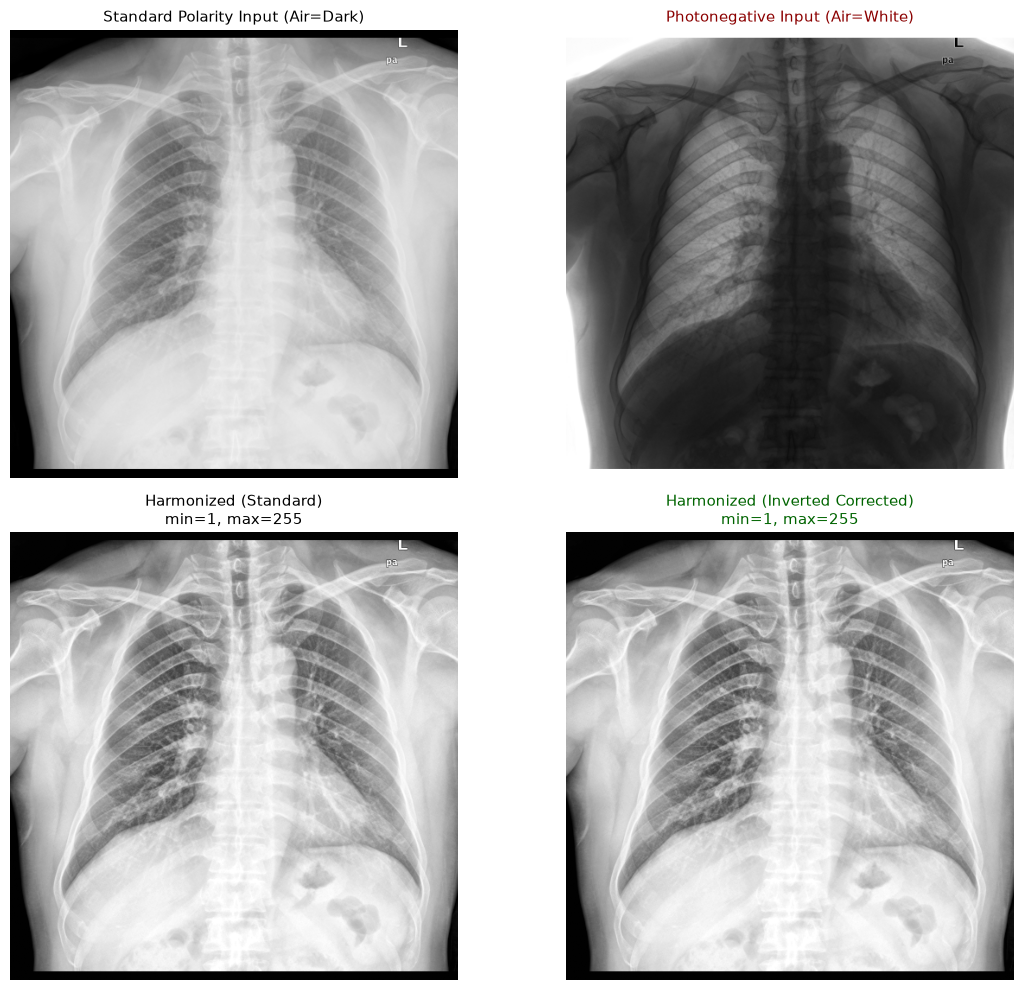

In [6]:
# Demonstrate Radiometric Harmonization on Normal and Inverted Radiographs
sample_img = res_518.copy()
# Create photonegative (inverted) radiograph
inverted_img = 255 - sample_img

harmonized_normal = harmonize_xray_radiometry(sample_img)
harmonized_inverted = harmonize_xray_radiometry(inverted_img)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(sample_img, cmap="gray")
axes[0, 0].set_title("Standard Polarity Input (Air=Dark)", fontsize=11)
axes[0, 0].axis("off")

axes[0, 1].imshow(inverted_img, cmap="gray")
axes[0, 1].set_title("Photonegative Input (Air=White)", fontsize=11, color="darkred")
axes[0, 1].axis("off")

axes[1, 0].imshow(harmonized_normal, cmap="gray")
axes[1, 0].set_title(f"Harmonized (Standard)\nmin={harmonized_normal.min()}, max={harmonized_normal.max()}", fontsize=11)
axes[1, 0].axis("off")

axes[1, 1].imshow(harmonized_inverted, cmap="gray")
axes[1, 1].set_title(f"Harmonized (Inverted Corrected)\nmin={harmonized_inverted.min()}, max={harmonized_inverted.max()}", fontsize=11, color="darkgreen")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

## 6. Anatomical Lung Masking & 3-Channel Dual Representation

Non-lung thoracic structures (external background, lead markers, cardiac silhouette, abdominal gas) comprise >50% of CXR pixels. Foundation models can inadvertently learn site-specific background artifacts as shortcuts.

We construct a **3-channel dual-representation tensor** $(3, 518, 518)$:
- **Channel 0**: Enhanced radiograph (global thoracic context).
- **Channel 1**: Parenchyma-isolated radiograph (`generate_lung_mask()` applied, zeroing background).
- **Channel 2**: High-contrast unsharp edge residual (`compute_high_pass_residual()`, highlighting cavitary rims and micro-calcifications).

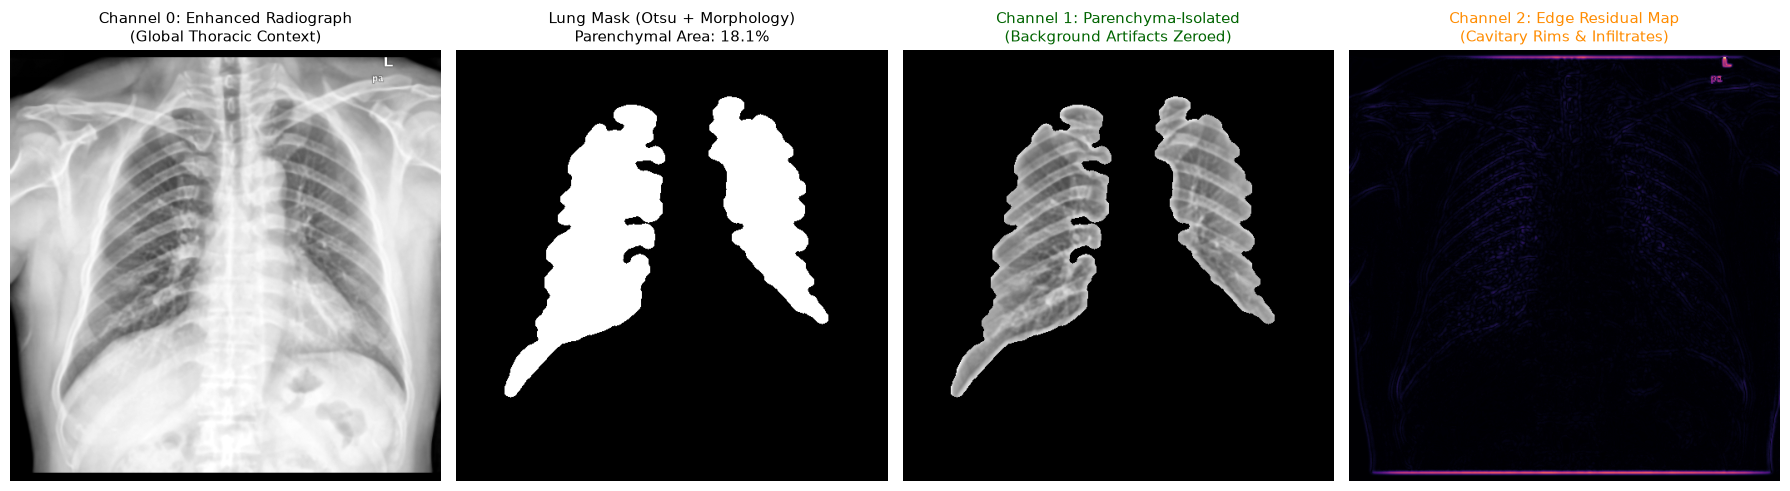

Dual-representation tensor shape: (518, 518, 3)


In [7]:
# Generate and visualize 3-channel dual-representation stream
preprocessed = preprocess_xray(sample_img)
mask = generate_lung_mask(preprocessed)
lung_isolated = cv2.bitwise_and(preprocessed, preprocessed, mask=mask)
edge_residual = compute_high_pass_residual(preprocessed)

# Construct 3-channel tensor
ch0 = preprocessed.astype(np.float32) / 255.0
ch1 = lung_isolated.astype(np.float32) / 255.0
ch2 = edge_residual.astype(np.float32) / 255.0
dual_stream = np.stack([ch0, ch1, ch2], axis=-1)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(ch0, cmap="gray")
axes[0].set_title("Channel 0: Enhanced Radiograph\n(Global Thoracic Context)", fontsize=11)
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title(f"Lung Mask (Otsu + Morphology)\nParenchymal Area: {(mask > 0).mean()*100:.1f}%", fontsize=11)
axes[1].axis("off")

axes[2].imshow(ch1, cmap="gray")
axes[2].set_title("Channel 1: Parenchyma-Isolated\n(Background Artifacts Zeroed)", fontsize=11, color="darkgreen")
axes[2].axis("off")

axes[3].imshow(ch2, cmap="magma")
axes[3].set_title("Channel 2: Edge Residual Map\n(Cavitary Rims & Infiltrates)", fontsize=11, color="darkorange")
axes[3].axis("off")

plt.tight_layout()
plt.show()

print(f"Dual-representation tensor shape: {dual_stream.shape}")

## 7. Cohort Production & Patient Grouping Verification

The full cohort of **7,800 chest radiographs** was generated into `data/processed_518/` with deterministic patient grouping and zero split leakage.

In [8]:
# Verify generated dataset manifest
manifest_path = REPO_ROOT / "data" / "processed_518" / "manifest.csv"
if manifest_path.exists():
    with open(manifest_path, "r") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
    print(f"Total Images in Dataset: {len(rows):,}")
    
    # Split distribution
    split_counts = defaultdict(lambda: defaultdict(int))
    patient_splits = defaultdict(set)
    for r in rows:
        split_counts[r["split"]][r["label"]] += 1
        patient_splits[(r["label"], r["patient_id"])].add(r["split"])
    
    print("\nCohort Split Distribution:")
    print(f"{'Split':<8} | {'Normal':>8} | {'TB':>8} | {'Total':>8}")
    print("-" * 38)
    for split in ["train", "val", "test"]:
        n_c = split_counts[split]["Normal"]
        tb_c = split_counts[split]["TB"]
        print(f"{split:<8} | {n_c:>8} | {tb_c:>8} | {n_c + tb_c:>8}")
    
    leakage = sum(1 for splits in patient_splits.values() if len(splits) > 1)
    print(f"\nCross-split patient leakage: {leakage} patients (ZERO LEAKAGE INVARIANT VERIFIED)")
    
    sample_png = REPO_ROOT / "data" / "processed_518" / rows[0]["filename"]
    disk_img = cv2.imread(str(sample_png), cv2.IMREAD_GRAYSCALE)
    print(f"Stored PNG shape: {disk_img.shape}, dtype: {disk_img.dtype}, range: [{disk_img.min()}, {disk_img.max()}]")
else:
    print(f"Manifest not found at {manifest_path}")

Total Images in Dataset: 7,800

Cohort Split Distribution:
Split    |   Normal |       TB |    Total
--------------------------------------
train    |     3580 |     3558 |     7138
val      |      163 |      168 |      331
test     |      163 |      168 |      331

Cross-split patient leakage: 0 patients (ZERO LEAKAGE INVARIANT VERIFIED)
Stored PNG shape: (518, 518), dtype: uint8, range: [1, 255]
